In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import const
import json_util
import pde_residual
import pinn_training
import plot_util
import synthetic_stokes_soret

plot_util.apply_plot_style()

RESULT = ROOT / "result" / "pinn_diffusion"
RESULT.mkdir(parents=True, exist_ok=True)
FIGURE = RESULT / "figure"
FIGURE.mkdir(exist_ok=True)

RESUME_TRAINING = True

FIELDS = ("u", "v", "w", "p", "T", "Y")
PROFILE_FIELDS = ("u", "T", "Y")
DIAG_GRID = (2, 3)
BOUNDS = ([const.SS_X_RANGE[0], const.SS_Y_RANGE[0], const.SS_Z_RANGE[0], const.SS_T_RANGE[0]],
          [const.SS_X_RANGE[1], const.SS_Y_RANGE[1], const.SS_Z_RANGE[1], const.SS_T_RANGE[1]])
INVERSE = {"mu": const.SS_MU_INIT, "D": const.SS_D_INIT, "DT": const.SS_DT_INIT}
KNOWN = {"rho": const.SS_RHO, "alpha": const.SS_ALPHA}
TRUE = {"mu": const.SS_MU_TRUE, "D": const.SS_D_TRUE, "DT": const.SS_DT_TRUE}


def neumann(axis):
    return lambda X, y: [pde_residual.grad(y[f], X)[:, axis:axis + 1] for f in FIELDS]


def wall(X, y):
    return [y["u"] - const.SS_U0, y["v"], y["w"], y["p"], y["T"] - const.SS_TW, y["Y"] - const.SS_YW]


def far(X, y):
    return [y[f] for f in FIELDS]


def initial(X, y):
    z, t = X[:, 2:3], X[:, 3:4]
    nu = const.SS_MU_TRUE / const.SS_RHO
    u = const.SS_U0 * torch.special.erfc(z / (2 * torch.sqrt(nu * t)))
    T = const.SS_TW * torch.special.erfc(z / (2 * torch.sqrt(const.SS_ALPHA * t)))
    C = const.SS_DT_TRUE * const.SS_TW / (const.SS_D_TRUE - const.SS_RHO * const.SS_ALPHA)
    Y = ((const.SS_YW + C) * torch.special.erfc(z / (2 * torch.sqrt(const.SS_D_TRUE / const.SS_RHO * t)))
         - C * torch.special.erfc(z / (2 * torch.sqrt(const.SS_ALPHA * t))))
    return [y["u"] - u, y["v"], y["w"], y["p"], y["T"] - T, y["Y"] - Y]


BOUNDARY = [{"name": "x_lo", "axis": 0, "side": "lo", "residual": neumann(0)},
            {"name": "x_hi", "axis": 0, "side": "hi", "residual": neumann(0)},
            {"name": "y_lo", "axis": 1, "side": "lo", "residual": neumann(1)},
            {"name": "y_hi", "axis": 1, "side": "hi", "residual": neumann(1)},
            {"name": "wall", "axis": 2, "side": "lo", "residual": wall},
            {"name": "far", "axis": 2, "side": "hi", "residual": far},
            {"name": "initial", "axis": 3, "side": "lo", "residual": initial}]

print("device:", "cuda " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

device: cuda NVIDIA GeForce RTX 5090


# 1. Synthetic Data

In [3]:
dataset = synthetic_stokes_soret.sample_synthetic_soret_dataset(
    n_samples=const.SS_N_SAMPLES, mu=const.SS_MU_TRUE, D=const.SS_D_TRUE, D_T=const.SS_DT_TRUE,
    alpha=const.SS_ALPHA, U0=const.SS_U0, rho=const.SS_RHO, Tw=const.SS_TW, Yw=const.SS_YW,
    x_range=const.SS_X_RANGE, y_range=const.SS_Y_RANGE, z_range=const.SS_Z_RANGE,
    t_range=const.SS_T_RANGE, noise_std=0.0, seed=const.SEED)
print({k: (v.shape if hasattr(v, "shape") else v) for k, v in dataset.items()})

{'X': (3000, 4), 'u': (3000, 1), 'v': (3000, 1), 'w': (3000, 1), 'p': (3000, 1), 'T': (3000, 1), 'Y': (3000, 1), 'mu_true': 0.08, 'D_true': 0.03, 'DT_true': 0.015, 'alpha': 0.12, 'U0_true': 1.0, 'rho': 1.0, 'Tw': 1.0, 'Yw': 1.0}


In [4]:
z_lin = np.linspace(*const.SS_Z_RANGE, const.SS_Z_N)
check = {"z_lin": z_lin, "t_snapshots": list(const.SS_CHECK_T_SNAPSHOTS), "sample_z": [],
         "exact": {f: [] for f in PROFILE_FIELDS}, "sample": {f: [] for f in PROFILE_FIELDS}}
for t_snap in const.SS_CHECK_T_SNAPSHOTS:
    exact = {
        "u": synthetic_stokes_soret.velocity_field(z_lin, t_snap, const.SS_U0, const.SS_MU_TRUE, const.SS_RHO)[0],
        "T": synthetic_stokes_soret.temperature_field(z_lin, t_snap, const.SS_ALPHA, const.SS_TW),
        "Y": synthetic_stokes_soret.species_field(z_lin, t_snap, const.SS_D_TRUE, const.SS_DT_TRUE,
                                                  const.SS_ALPHA, const.SS_RHO, const.SS_YW, const.SS_TW)}
    mask = np.abs(dataset["X"][:, 3] - t_snap) <= const.SS_CHECK_T_TOL
    check["sample_z"].append(dataset["X"][mask, 2])
    for f in PROFILE_FIELDS:
        check["exact"][f].append(exact[f])
        check["sample"][f].append(dataset[f][mask, 0])
json_util.save_json(RESULT / "dataset_check.json", check)
print({t: len(sz) for t, sz in zip(check["t_snapshots"], check["sample_z"])})

{0.1: 108, 0.4: 196, 0.7: 213, 1.0: 101}


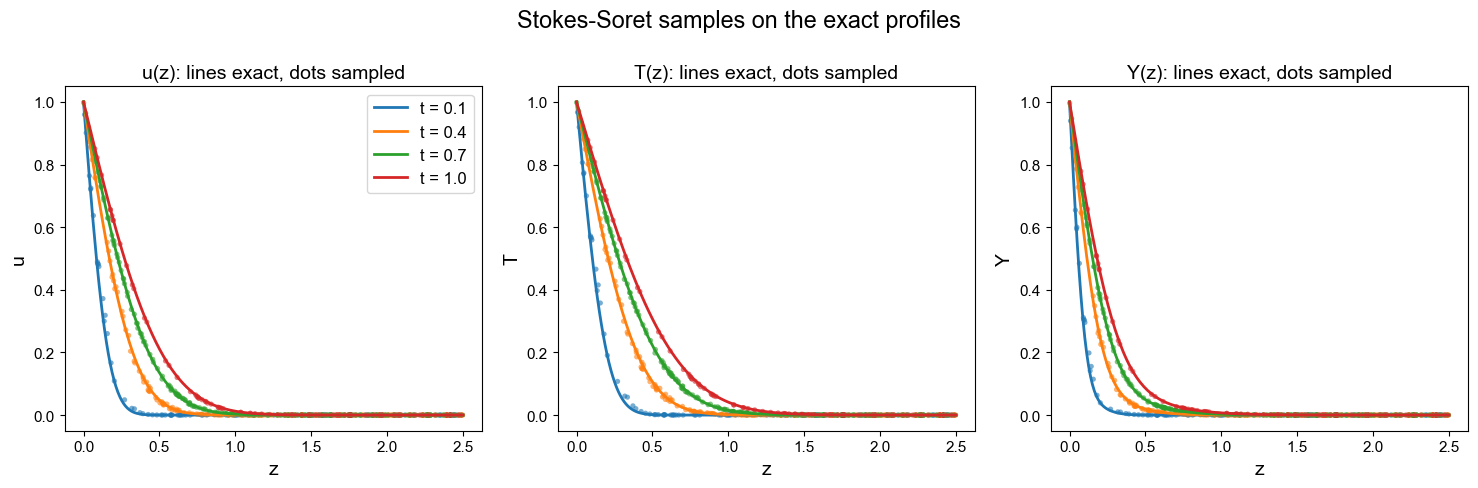

In [5]:
check = json_util.load_json(RESULT / "dataset_check.json")
z_lin = check["z_lin"]
n = len(PROFILE_FIELDS)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
for ax, f in zip(axes, PROFILE_FIELDS):
    for i, t_snap in enumerate(check["t_snapshots"]):
        ax.plot(z_lin, check["exact"][f][i], color=f"C{i}", label=f"t = {t_snap}")
        ax.scatter(check["sample_z"][i], check["sample"][f][i], color=f"C{i}", s=14, alpha=0.6,
                   edgecolors="none")
    ax.set_xlabel("z")
    ax.set_ylabel(f)
    ax.set_title(f"{f}(z): lines exact, dots sampled")
axes[0].legend()
fig.suptitle("Stokes-Soret samples on the exact profiles")
fig.tight_layout()
fig.savefig(FIGURE / "dataset_check.png")
plt.show()

# 2. Train PINN

In [6]:
RERUN_TRAIN = False
ckpt = RESULT / "main.pt"
path = RESULT / "main.json"
if RERUN_TRAIN or not (ckpt.exists() and path.exists()):
    trainer = pinn_training.PINNTraining(dataset, inverse=INVERSE, known=KNOWN, bounds=BOUNDS, boundary=BOUNDARY,
                                         checkpoint_path=ckpt, resume=RESUME_TRAINING)
    res = trainer.train()
    te = trainer.test_data
    z_lin = np.linspace(*const.SS_Z_RANGE, const.SS_Z_N)
    t_snap = const.SS_RECON_T
    grid = np.column_stack([np.zeros_like(z_lin), np.zeros_like(z_lin), z_lin, np.full_like(z_lin, t_snap)])
    pred_grid = trainer.evaluate(grid)
    exact = {
        "u": synthetic_stokes_soret.velocity_field(z_lin, t_snap, const.SS_U0, const.SS_MU_TRUE, const.SS_RHO)[0],
        "T": synthetic_stokes_soret.temperature_field(z_lin, t_snap, const.SS_ALPHA, const.SS_TW),
        "Y": synthetic_stokes_soret.species_field(z_lin, t_snap, const.SS_D_TRUE, const.SS_DT_TRUE,
                                                  const.SS_ALPHA, const.SS_RHO, const.SS_YW, const.SS_TW)}
    rec = {"params": res["params"], "true": TRUE,
           "split": {"train": int(trainer.train_data["X"].shape[0]), "valid": int(trainer.valid_data["X"].shape[0]),
                     "test": int(te["X"].shape[0])},
           "n_colloc": res["config"]["n_colloc"],
           "residual": {s: pinn_training.PINNTraining.residual_stats(trainer.evaluate_residual(s))
                        for s in ("train", "valid", "test")},
           "history": res["history"],
           "best": res["best"],
           "test": trainer.diag_record("test"),
           "field": {"t": t_snap, "z_lin": z_lin, "exact": exact,
                     "pred": {f: pred_grid[f] for f in PROFILE_FIELDS}},
           "loss": res["loss"], "terms": res["terms"], "wall_seconds": res["wall_seconds"],
           "config": res["config"]}
    json_util.save_json(path, rec)
main = json_util.load_json(path)
print(f"split: {main['split']}   wall: {main['wall_seconds'] / 60:.1f} min   final loss: {main['loss']:.3e}")
for k, v in main["params"].items():
    print(f"{k}: true = {main['true'][k]}   recovered = {v:.5f}   rel_error = {abs(v - main['true'][k]) / main['true'][k]:.2%}")

split: {'train': 2400, 'valid': 300, 'test': 300}   wall: 16.5 min   final loss: 6.335e-07
mu: true = 0.08   recovered = 0.07996   rel_error = 0.05%
D: true = 0.03   recovered = 0.02997   rel_error = 0.09%
DT: true = 0.015   recovered = 0.01505   rel_error = 0.32%


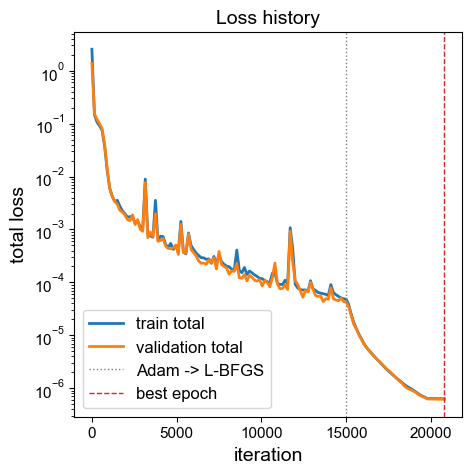

<Axes: title={'center': 'Loss history'}, xlabel='iteration', ylabel='total loss'>

In [7]:
main = json_util.load_json(RESULT / "main.json")
pinn_training.PINNTraining.plot_loss(main["history"], FIGURE / "main_loss.png",
                     best_iteration=main.get("best", {}).get("iteration"))

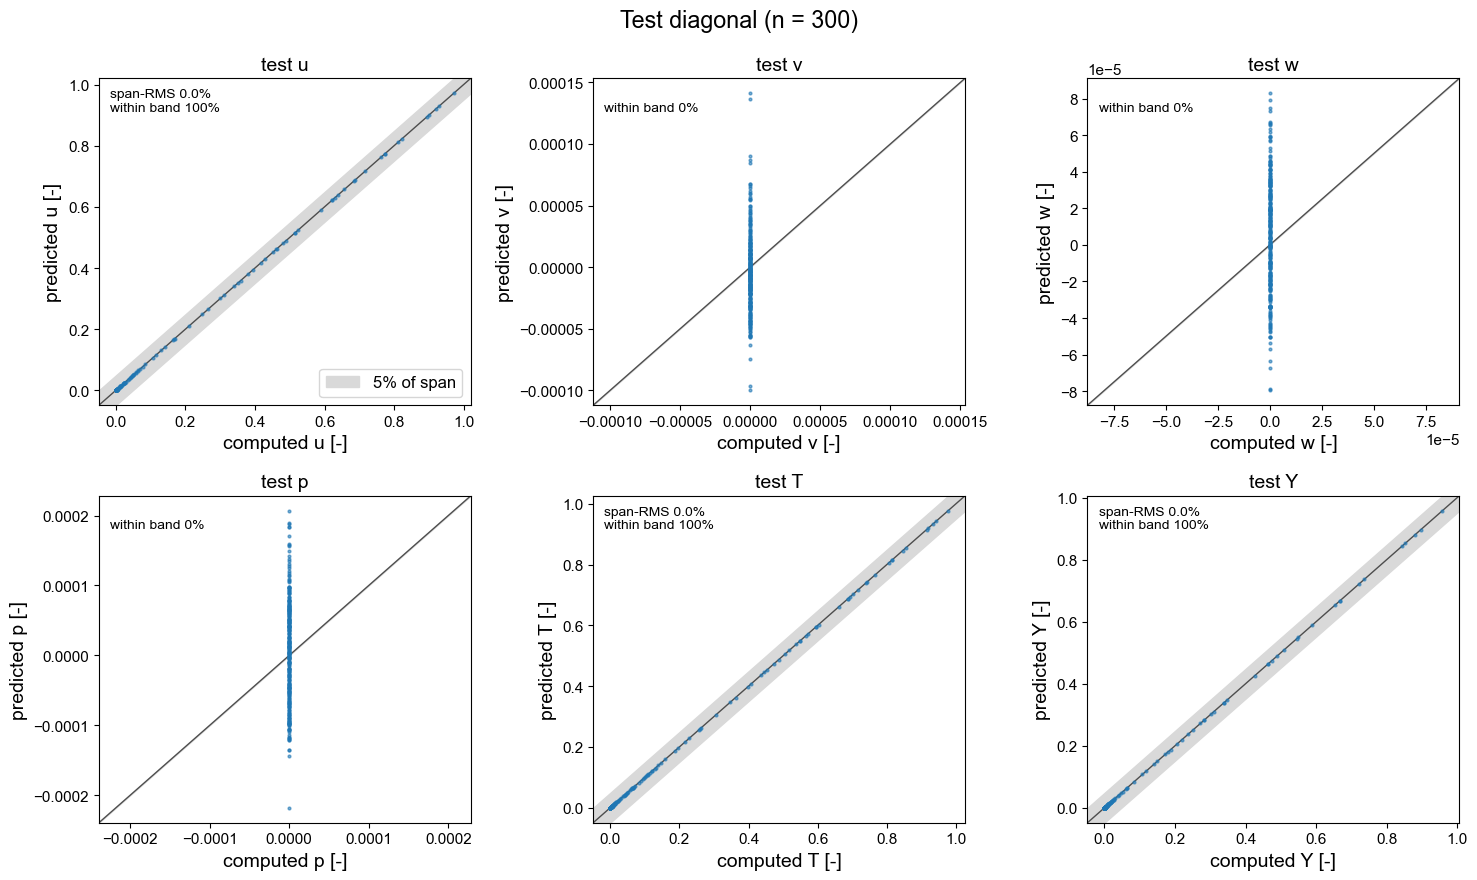

array([<Axes: title={'center': 'test u'}, xlabel='computed u [-]', ylabel='predicted u [-]'>,
       <Axes: title={'center': 'test v'}, xlabel='computed v [-]', ylabel='predicted v [-]'>,
       <Axes: title={'center': 'test w'}, xlabel='computed w [-]', ylabel='predicted w [-]'>,
       <Axes: title={'center': 'test p'}, xlabel='computed p [-]', ylabel='predicted p [-]'>,
       <Axes: title={'center': 'test T'}, xlabel='computed T [-]', ylabel='predicted T [-]'>,
       <Axes: title={'center': 'test Y'}, xlabel='computed Y [-]', ylabel='predicted Y [-]'>],
      dtype=object)

In [8]:
main = json_util.load_json(RESULT / "main.json")
pinn_training.PINNTraining.plot_diag(main["test"], FIELDS, DIAG_GRID, FIGURE / "main_diag.png",
                     title=f"Test diagonal (n = {main['split']['test']})")

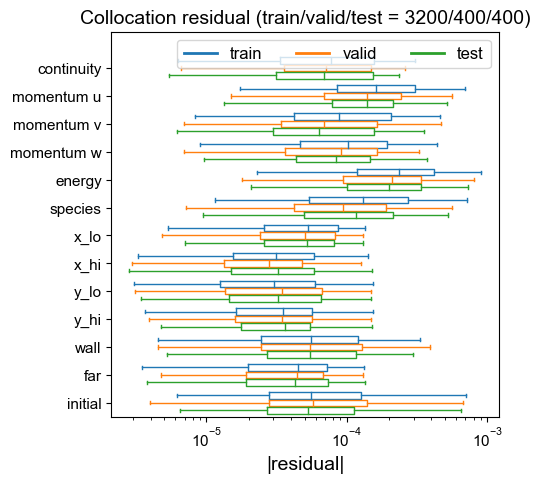

<Axes: title={'center': 'Collocation residual (train/valid/test = 3200/400/400)'}, xlabel='|residual|'>

In [9]:
main = json_util.load_json(RESULT / "main.json")
n_colloc = main["n_colloc"]
pinn_training.PINNTraining.plot_residual(
    main["residual"], FIGURE / "main_residual.png",
    title=f"Collocation residual (train/valid/test = {n_colloc['train']}/{n_colloc['valid']}/{n_colloc['test']})")


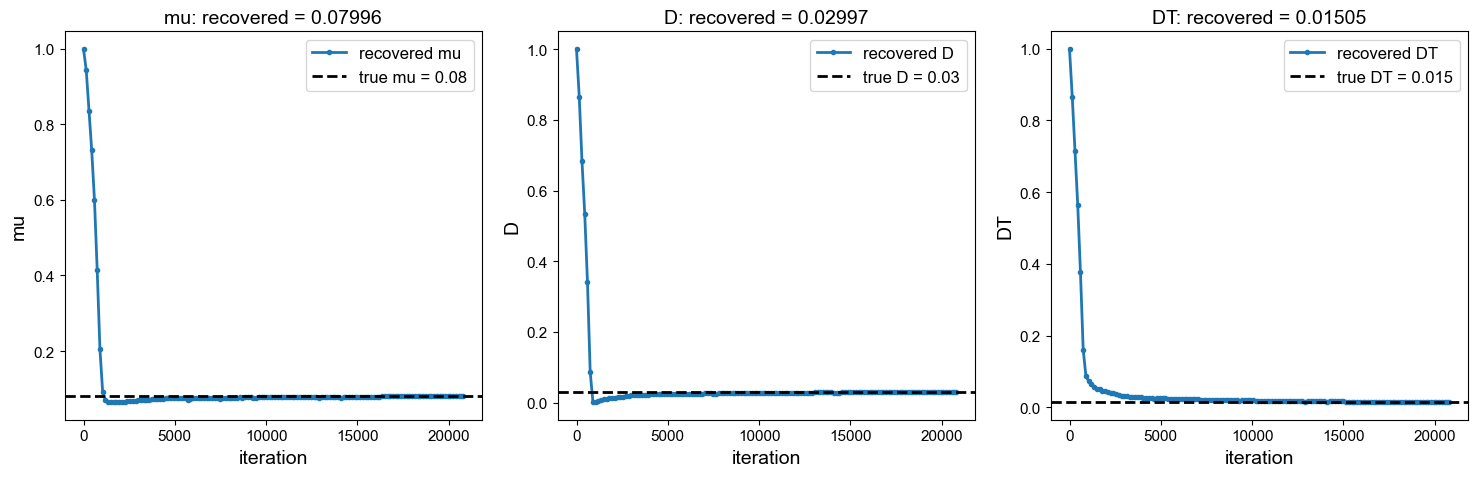

mu: true = 0.08   recovered = 0.07996   rel_error = 0.05%
D: true = 0.03   recovered = 0.02997   rel_error = 0.09%
DT: true = 0.015   recovered = 0.01505   rel_error = 0.32%


In [10]:
main = json_util.load_json(RESULT / "main.json")
h = main["history"]
names = list(main["params"])
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 5), squeeze=False)
for ax, k in zip(axes[0], names):
    ax.plot(h["iteration"], h[k], marker="o", ms=3, label=f"recovered {k}")
    ax.axhline(main["true"][k], color="k", ls="--", label=f"true {k} = {main['true'][k]}")
    ax.set_xlabel("iteration")
    ax.set_ylabel(k)
    ax.set_title(f"{k}: recovered = {main['params'][k]:.5f}")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURE / "main_params.png")
plt.show()
for k in names:
    print(f"{k}: true = {main['true'][k]}   recovered = {main['params'][k]:.5f}   "
          f"rel_error = {abs(main['params'][k] - main['true'][k]) / main['true'][k]:.2%}")

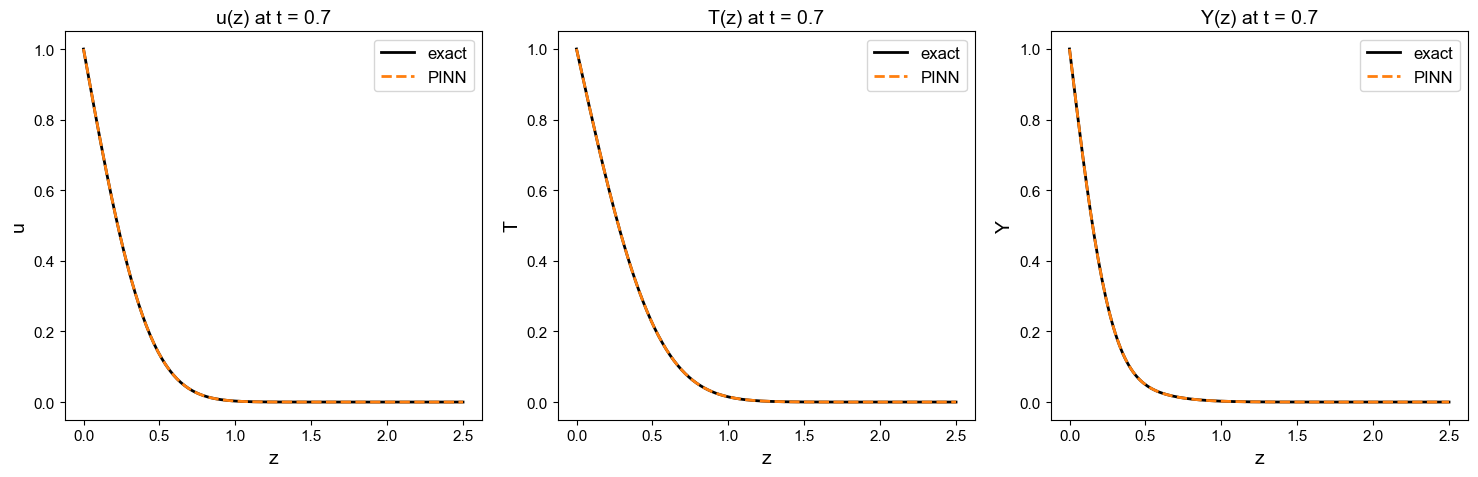

In [11]:
main = json_util.load_json(RESULT / "main.json")
fld = main["field"]
n = len(PROFILE_FIELDS)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
for ax, f in zip(axes, PROFILE_FIELDS):
    ax.plot(fld["z_lin"], fld["exact"][f], "k-", label="exact")
    ax.plot(fld["z_lin"], fld["pred"][f], "C1--", label="PINN")
    ax.set_xlabel("z")
    ax.set_ylabel(f)
    ax.set_title(f"{f}(z) at t = {fld['t']}")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURE / "main_field.png")
plt.show()

# 3. Noise Sensitivity

In [12]:
RERUN_NOISE = False
path = RESULT / "noise_sweep.json"
if RERUN_NOISE or not path.exists():
    records = []
    for noise_std in const.NOISE_LEVELS:
        for seed in range(const.N_REPEATS):
            ds = synthetic_stokes_soret.sample_synthetic_soret_dataset(
                n_samples=const.SS_N_SAMPLES, mu=const.SS_MU_TRUE, D=const.SS_D_TRUE, D_T=const.SS_DT_TRUE,
                alpha=const.SS_ALPHA, U0=const.SS_U0, rho=const.SS_RHO, Tw=const.SS_TW, Yw=const.SS_YW,
                x_range=const.SS_X_RANGE, y_range=const.SS_Y_RANGE, z_range=const.SS_Z_RANGE,
                t_range=const.SS_T_RANGE, noise_std=noise_std, seed=seed)
            ckpt = RESULT / "noise_sweep" / f"noise_{noise_std}_seed_{seed}.pt"
            ckpt.parent.mkdir(exist_ok=True)
            trainer = pinn_training.PINNTraining(ds, inverse=INVERSE, known=KNOWN, bounds=BOUNDS, boundary=BOUNDARY,
                                                 adam_iterations=const.SWEEP_ADAM_ITERATIONS,
                                                 lbfgs_iterations=const.SWEEP_LBFGS_ITERATIONS,
                                                 seed=seed, log_every=0,
                                                 checkpoint_path=ckpt, resume=RESUME_TRAINING)
            res = trainer.train()
            records.append({"noise_std": noise_std, "n_samples": const.SS_N_SAMPLES, "seed": seed, "params": res["params"],
                            "best": res["best"],
                            "loss": res["loss"], "val_total": res["history"]["val_total"][-1],
                            "wall_seconds": res["wall_seconds"]})
            print(f"noise_std={records[-1]['noise_std']:<6} seed={seed}  " + "  ".join(
                f"{k}={v:.5f} ({abs(v - TRUE[k]) / TRUE[k]:.2%})" for k, v in res["params"].items()))
    json_util.save_json(path, {"records": records, "true": TRUE})
sweep = json_util.load_json(path)
print(f"{len(sweep['records'])} runs")

12 runs


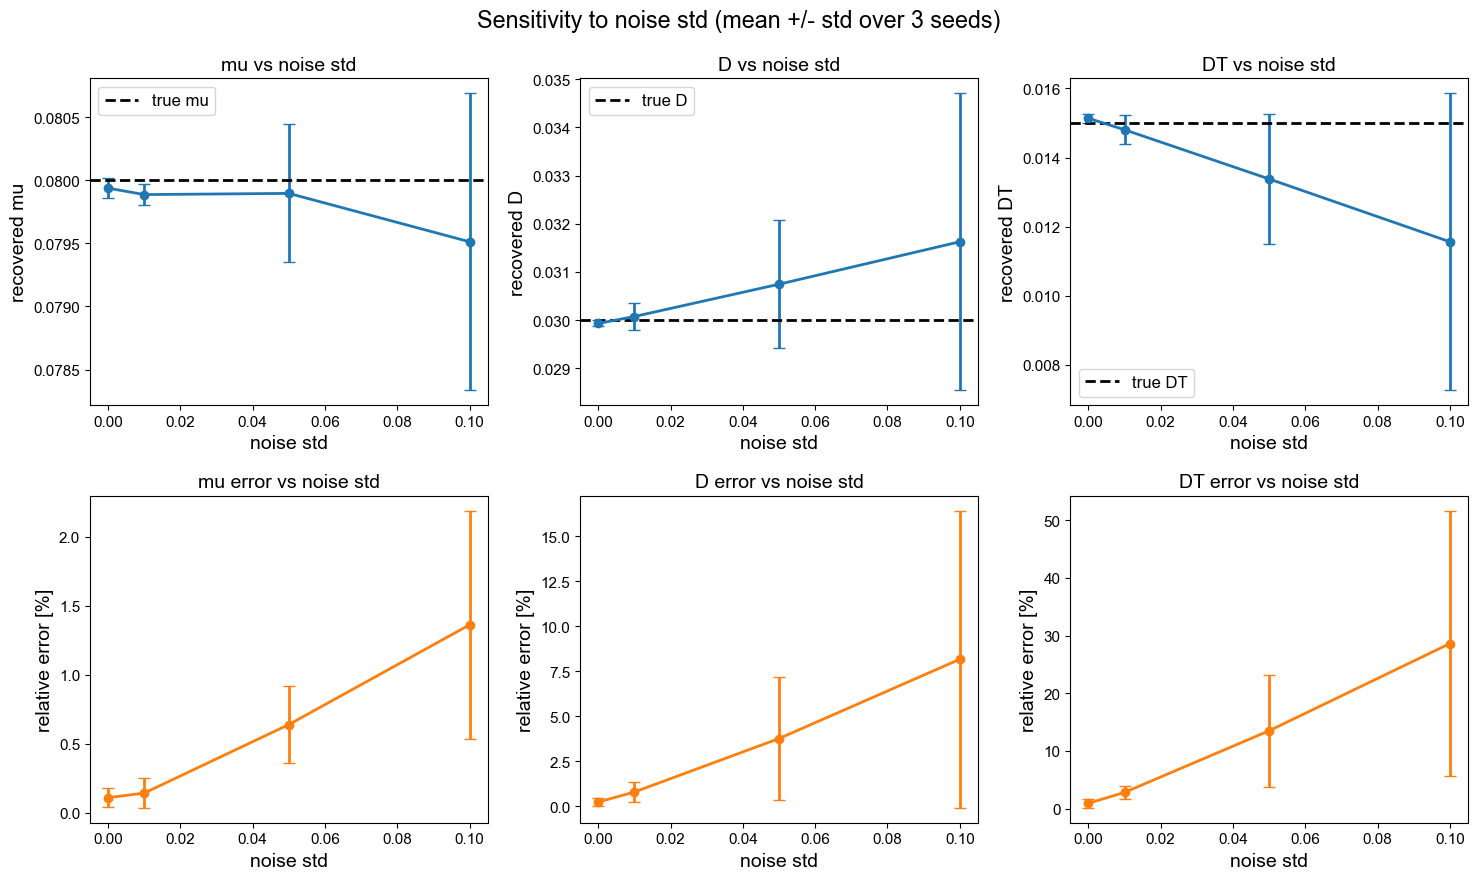

In [13]:
sweep = json_util.load_json(RESULT / "noise_sweep.json")
levels = sorted({r["noise_std"] for r in sweep["records"]})
names = list(sweep["true"])
fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 9), squeeze=False)
for j, k in enumerate(names):
    vals = np.array([[r["params"][k] for r in sweep["records"] if r["noise_std"] == lv] for lv in levels])
    rel = np.abs(vals - sweep["true"][k]) / sweep["true"][k]
    axes[0, j].errorbar(levels, vals.mean(axis=1), yerr=vals.std(axis=1), marker="o", capsize=4)
    axes[0, j].axhline(sweep["true"][k], color="k", ls="--", label=f"true {k}")
    axes[0, j].set_xlabel("noise std")
    axes[0, j].set_ylabel(f"recovered {k}")
    axes[0, j].set_title(f"{k} vs noise std")
    axes[0, j].legend()
    axes[1, j].errorbar(levels, 100 * rel.mean(axis=1), yerr=100 * rel.std(axis=1), marker="o",
                        capsize=4, color="C1")
    axes[1, j].set_xlabel("noise std")
    axes[1, j].set_ylabel("relative error [%]")
    axes[1, j].set_title(f"{k} error vs noise std")
fig.suptitle(f"Sensitivity to noise std (mean +/- std over {const.N_REPEATS} seeds)")
fig.tight_layout()
fig.savefig(FIGURE / "noise_sweep.png")
plt.show()

# 4. Sample Number Sensitivity

In [14]:
RERUN_SAMPLE = False
path = RESULT / "sample_sweep.json"
if RERUN_SAMPLE or not path.exists():
    records = []
    for n_samples in const.SAMPLE_COUNTS:
        for seed in range(const.N_REPEATS):
            ds = synthetic_stokes_soret.sample_synthetic_soret_dataset(
                n_samples=n_samples, mu=const.SS_MU_TRUE, D=const.SS_D_TRUE, D_T=const.SS_DT_TRUE,
                alpha=const.SS_ALPHA, U0=const.SS_U0, rho=const.SS_RHO, Tw=const.SS_TW, Yw=const.SS_YW,
                x_range=const.SS_X_RANGE, y_range=const.SS_Y_RANGE, z_range=const.SS_Z_RANGE,
                t_range=const.SS_T_RANGE, noise_std=0.0, seed=seed)
            ckpt = RESULT / "sample_sweep" / f"n_{n_samples}_seed_{seed}.pt"
            ckpt.parent.mkdir(exist_ok=True)
            trainer = pinn_training.PINNTraining(ds, inverse=INVERSE, known=KNOWN, bounds=BOUNDS, boundary=BOUNDARY,
                                                 adam_iterations=const.SWEEP_ADAM_ITERATIONS,
                                                 lbfgs_iterations=const.SWEEP_LBFGS_ITERATIONS,
                                                 seed=seed, log_every=0,
                                                 checkpoint_path=ckpt, resume=RESUME_TRAINING)
            res = trainer.train()
            records.append({"n_samples": n_samples, "noise_std": 0.0, "seed": seed, "params": res["params"],
                            "best": res["best"],
                            "loss": res["loss"], "val_total": res["history"]["val_total"][-1],
                            "wall_seconds": res["wall_seconds"]})
            print(f"n_samples={records[-1]['n_samples']:<6} seed={seed}  " + "  ".join(
                f"{k}={v:.5f} ({abs(v - TRUE[k]) / TRUE[k]:.2%})" for k, v in res["params"].items()))
    json_util.save_json(path, {"records": records, "true": TRUE})
sweep = json_util.load_json(path)
print(f"{len(sweep['records'])} runs")

15 runs


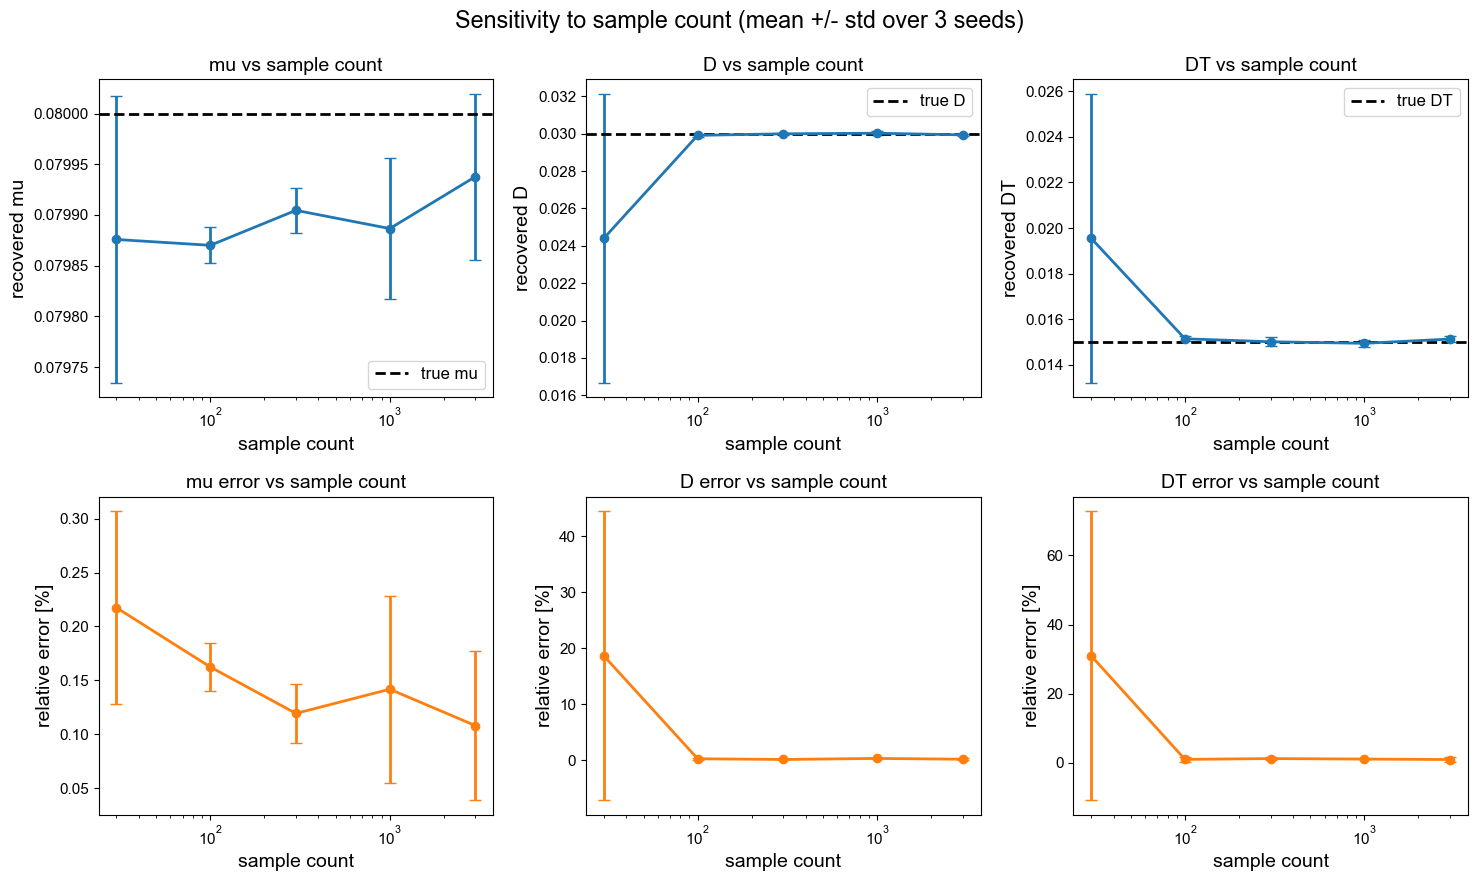

In [15]:
sweep = json_util.load_json(RESULT / "sample_sweep.json")
levels = sorted({r["n_samples"] for r in sweep["records"]})
names = list(sweep["true"])
fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 9), squeeze=False)
for j, k in enumerate(names):
    vals = np.array([[r["params"][k] for r in sweep["records"] if r["n_samples"] == lv] for lv in levels])
    rel = np.abs(vals - sweep["true"][k]) / sweep["true"][k]
    axes[0, j].errorbar(levels, vals.mean(axis=1), yerr=vals.std(axis=1), marker="o", capsize=4)
    axes[0, j].axhline(sweep["true"][k], color="k", ls="--", label=f"true {k}")
    axes[0, j].set_xlabel("sample count")
    axes[0, j].set_ylabel(f"recovered {k}")
    axes[0, j].set_title(f"{k} vs sample count")
    axes[0, j].legend()
    axes[1, j].errorbar(levels, 100 * rel.mean(axis=1), yerr=100 * rel.std(axis=1), marker="o",
                        capsize=4, color="C1")
    axes[1, j].set_xlabel("sample count")
    axes[1, j].set_ylabel("relative error [%]")
    axes[1, j].set_title(f"{k} error vs sample count")
    axes[0, j].set_xscale("log")
    axes[1, j].set_xscale("log")
fig.suptitle(f"Sensitivity to sample count (mean +/- std over {const.N_REPEATS} seeds)")
fig.tight_layout()
fig.savefig(FIGURE / "sample_sweep.png")
plt.show()